#  Лаба 1 (возможны изменения)

## Задание на л/р 1 
1. Проделать те же шаги, что и в данном юпитер-примере для распределений: Хи-квадрат, Стьюдента, Фишера и ещё одно распределение выбрать самостоятельно.
2. Посчтитать статистики для выборок (лекция 1, слайды 36-37):
- выборочное среднее
- выборочная дисперсия
- выборочный квантиль уровня 0.06
- выборочная медиана (реализовать формулу самостоятельно)
- выборочный интерквартильный размах
- выборочный коэффициент ассиметрии
- выборочный коэффициент эксцесса
3. Убедиться в верности сходимостей на слайде 21.
(вписать формулы с слайдов)
в случае нормального распределения проверить для любых а

ЦПТ проверить для распределений Хи-квадрат, Стьюдента, Фишера и выбранное распределение

проверить ЗБЧ: Для выбранного распределения, для любого дискретного распределения и для распределения Коши.


Делать в отдельном ipynb-файле.

In [2]:
import numpy as np             
from scipy import stats 
import matplotlib.pyplot as plt
import seaborn as sns

#plt.style.use('ggplot')    # стиль графиков

# 1. Генерация случайных величин в python

Чтобы сгенерировать случайную величину, нужно создать генератор с параметрами распределения: 

Выбрать генератор распределения можно из пакета `scipy.stats`: https://docs.scipy.org/doc/scipy-0.14.0/reference/stats.html. 

Для нормального распределения $$ f(x) = \frac{1}{\sigma \sqrt{2 \pi}} \cdot  e^{-\frac{(x - \mu)^2}{2 \sigma^2}}
$$ необходимо задать два параметра:

```loc``` — мат. ожидание $\mu$ (сдвиг), ```scale``` — среднеквадратичное отклонение $\sigma$ (масштаб).

In [3]:
norm_rv = stats.norm(loc=0, scale=1)  # генератор нормального распределения

Когда конкретный генератор готов, у него можно вызывать разные методы: 

* `rvs` сгенерирует из распределения объёма `size`
* `cdf` вычислит значение функции распределения (cumulative distribution function) в указанной точке
* `pdf` вычислит значение плотности распределния (probability density function) в указанной точке 
* `ppf` вычислит квантиль, указанного уровня

Другие методы: https://docs.scipy.org/doc/scipy-0.14.0/reference/stats.html

In [4]:
sample = norm_rv.rvs(10000, random_state=1)  # выборка
#sample

In [4]:
sample_pdf = norm_rv.pdf(sample)  # значения плотности вероятности для элементов выборки 
sample_pdf

array([0.10665164, 0.33085949, 0.34700322, 0.22434519, 0.27433543,
       0.02822693, 0.08706306, 0.29859817, 0.37914692, 0.38672891,
       0.13699397, 0.04778572, 0.37873635, 0.37057945, 0.20978856,
       0.21787823, 0.39305557, 0.2713743 , 0.39858698, 0.3366285 ])

In [5]:
# значения плотности для элементов выборки также можно получить, задав формулу
x = sample
1 / np.sqrt(2 * np.pi) * np.exp(-(x ** 2) / 2)

array([0.10665164, 0.33085949, 0.34700322, 0.22434519, 0.27433543,
       0.02822693, 0.08706306, 0.29859817, 0.37914692, 0.38672891,
       0.13699397, 0.04778572, 0.37873635, 0.37057945, 0.20978856,
       0.21787823, 0.39305557, 0.2713743 , 0.39858698, 0.3366285 ])

# 2. Плотность и функция распределения


Значение плотности в точке, например, $f(1)$.

In [6]:
norm_rv.pdf(1)

np.float64(0.24197072451914337)

Можем построить картинку для плотности распределения, $f(x)$. 

In [7]:
x = np.linspace(-3, 3, 100)
print(x)
pdf = norm_rv.pdf(x)
pdf

[-3.         -2.93939394 -2.87878788 -2.81818182 -2.75757576 -2.6969697
 -2.63636364 -2.57575758 -2.51515152 -2.45454545 -2.39393939 -2.33333333
 -2.27272727 -2.21212121 -2.15151515 -2.09090909 -2.03030303 -1.96969697
 -1.90909091 -1.84848485 -1.78787879 -1.72727273 -1.66666667 -1.60606061
 -1.54545455 -1.48484848 -1.42424242 -1.36363636 -1.3030303  -1.24242424
 -1.18181818 -1.12121212 -1.06060606 -1.         -0.93939394 -0.87878788
 -0.81818182 -0.75757576 -0.6969697  -0.63636364 -0.57575758 -0.51515152
 -0.45454545 -0.39393939 -0.33333333 -0.27272727 -0.21212121 -0.15151515
 -0.09090909 -0.03030303  0.03030303  0.09090909  0.15151515  0.21212121
  0.27272727  0.33333333  0.39393939  0.45454545  0.51515152  0.57575758
  0.63636364  0.6969697   0.75757576  0.81818182  0.87878788  0.93939394
  1.          1.06060606  1.12121212  1.18181818  1.24242424  1.3030303
  1.36363636  1.42424242  1.48484848  1.54545455  1.60606061  1.66666667
  1.72727273  1.78787879  1.84848485  1.90909091  1.9

array([0.00443185, 0.00530579, 0.00632878, 0.00752133, 0.00890582,
       0.0105065 , 0.01234943, 0.01446241, 0.01687483, 0.01961746,
       0.02272223, 0.02622189, 0.03014961, 0.03453857, 0.03942137,
       0.0448295 , 0.05079264, 0.05733801, 0.06448952, 0.07226707,
       0.08068571, 0.08975477, 0.09947714, 0.10984842, 0.12085626,
       0.13247967, 0.14468855, 0.15744319, 0.17069405, 0.18438164,
       0.1984366 , 0.21277993, 0.22732351, 0.24197072, 0.2566174 ,
       0.27115285, 0.28546117, 0.29942268, 0.31291556, 0.3258175 ,
       0.33800759, 0.34936814, 0.35978656, 0.36915722, 0.37738323,
       0.38437808, 0.3900672 , 0.39438923, 0.39729716, 0.39875915,
       0.39875915, 0.39729716, 0.39438923, 0.3900672 , 0.38437808,
       0.37738323, 0.36915722, 0.35978656, 0.34936814, 0.33800759,
       0.3258175 , 0.31291556, 0.29942268, 0.28546117, 0.27115285,
       0.2566174 , 0.24197072, 0.22732351, 0.21277993, 0.1984366 ,
       0.18438164, 0.17069405, 0.15744319, 0.14468855, 0.13247

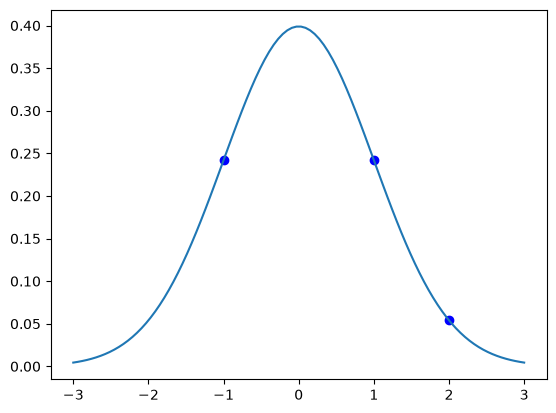

In [8]:
plt.plot(x, pdf)
# plt.ylabel('$f(x)$')
# plt.xlabel('$x$')

# На ней же нарисуем f(1)
plt.scatter([-1, 1, 2], [norm_rv.pdf(-1),norm_rv.pdf(1), norm_rv.pdf(2)], color="blue");

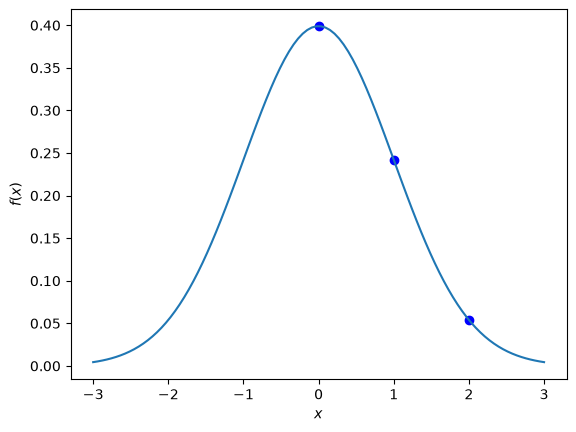

In [9]:
plt.plot(x, pdf)
plt.ylabel('$f(x)$')
plt.xlabel('$x$')

# На ней же нарисуем f(1)
plt.scatter([0,1,2], [norm_rv.pdf(0), norm_rv.pdf(1), norm_rv.pdf(2)], color="blue");

Теперь узнаем значение функции распределения в точке $1$: $$F(1) = P(X \le 1) = \int_{-\infty}^1 f(x)dx$$

In [10]:
norm_rv.cdf(1)

np.float64(0.8413447460685429)

На плотности распределения это выглядит как площадь до точки $1$, то есть вероятность того, что $X \le 1$.

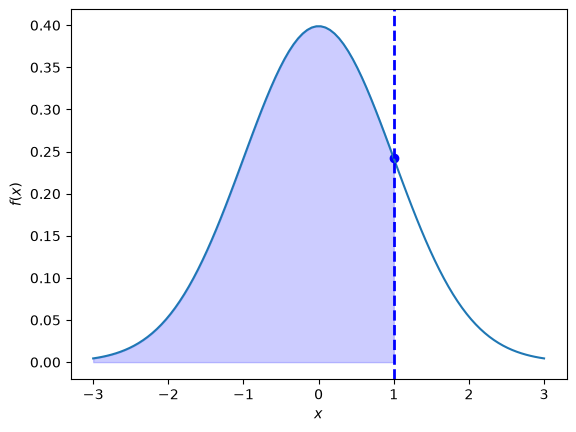

In [11]:
x = np.linspace(-3, 3, 100)
pdf = norm_rv.pdf(x)

plt.plot(x, pdf)
plt.ylabel('$f(x)$')
plt.xlabel('$x$')

# На ней же нарисуем f(1)
plt.scatter([1], [norm_rv.pdf(1)], color="blue");

# на ту же картинку добавили новую часть, штриховку
xq = np.linspace(-3, 1, 100)
yq = norm_rv.pdf(xq)
plt.fill_between(xq, 0, yq, color='blue', alpha=0.2)

plt.axvline(1, color='blue', linestyle="--", lw=2);

## Построение графика функции распределения

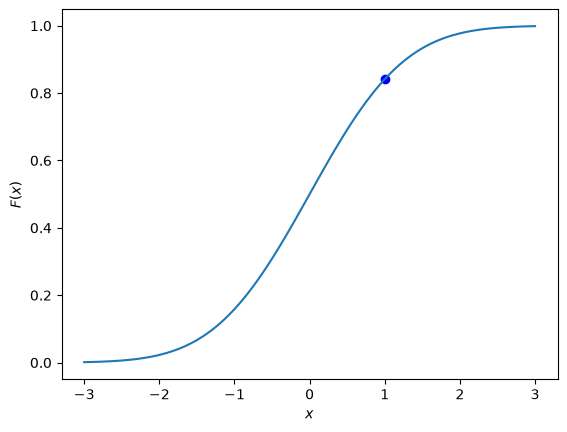

In [12]:
x = np.linspace(-3, 3, 100)
cdf = norm_rv.cdf(x)

plt.plot(x, cdf)
plt.ylabel('$F(x)$')
plt.xlabel('$x$')

# На ней же нарисуем F(1)
plt.scatter([1], [norm_rv.cdf(1)], color="blue");

Можно найти вероятность попадания в отрезок, например,

$$ P(1 < X < 3) = \int_1^3 f(x) dx = F(3) - F(1)$$

In [13]:
norm_rv.cdf(3) - norm_rv.cdf(1)

np.float64(0.15730535589982697)

Это уже вероятность попасть в конкретный отрезок, изобразим её на плотности распределения. 

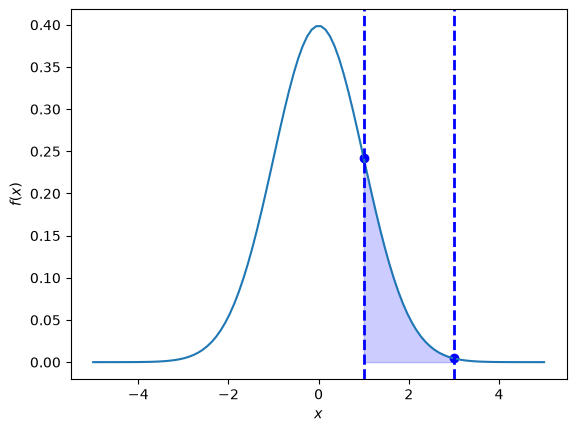

In [14]:
x = np.linspace(-5, 5, 100)
pdf = norm_rv.pdf(x)

plt.plot(x, pdf)
plt.ylabel('$f(x)$')
plt.xlabel('$x$')

# На ней же нарисуем f(1)
plt.scatter([1, 3], [norm_rv.pdf(1), norm_rv.pdf(3)], color="blue");

# на ту же картинку добавили новую часть, штриховку
xq = np.linspace(1, 3)
yq = norm_rv.pdf(xq)
plt.fill_between(xq, 0, yq, color='blue', alpha=0.2)

plt.axvline(1, color='blue', linestyle="--", lw=2)
plt.axvline(3, color='blue', linestyle="--", lw=2);

## Квантили распределения
Квантиль уровня $\gamma$ это такое число $q$, что 

$$P(X \le q) = \gamma$$

Найдём $5\%$ и нарисуем его на картинке с плотностью:

In [41]:
# здесь использовано правило трёх сигм. Для своих выборок можете использовать например функцию np.quantile()
uroven = (1 - 0.6826)/2
q = norm_rv.ppf(uroven)
q

np.float64(-0.9998150936147444)

In [48]:
nq = np.quantile(sample, (1 - 0.6826)/2)
nq

np.float64(-0.9922083759081965)

Text(-0.8922083759081966, 0.3349576888171431, '-0.99')

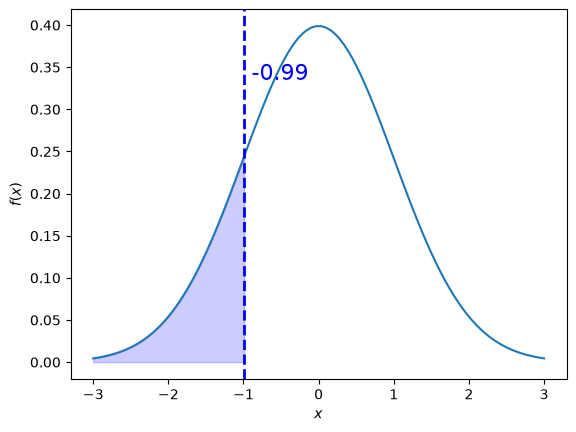

In [49]:
x = np.linspace(-3, 3, 100)
pdf = norm_rv.pdf(x)

plt.plot(x, pdf)
plt.ylabel('$f(x)$')
plt.xlabel('$x$')

xq = np.linspace(-3, nq)
yq = norm_rv.pdf(xq)
plt.fill_between(xq, 0, yq, color='blue', alpha=0.2)

plt.axvline(nq, color='blue', linestyle="--", lw=2)

y_max = plt.ylim()[1]
plt.text(nq + 0.1, 0.8*y_max, round(nq,2), color='blue', fontsize=16)

# 3. Эмпирическое распределение 

Анализ выборки.

In [19]:
sample[:10]

array([ 1.62434536, -0.61175641, -0.52817175, -1.07296862,  0.86540763,
       -2.3015387 ,  1.74481176, -0.7612069 ,  0.3190391 , -0.24937038])

In [20]:
sample.shape

(20,)

In [21]:
np.mean(sample)  # выборочное среднее

np.float64(-0.1333646364607294)

# Сравнение графиков гистограммы и плотности

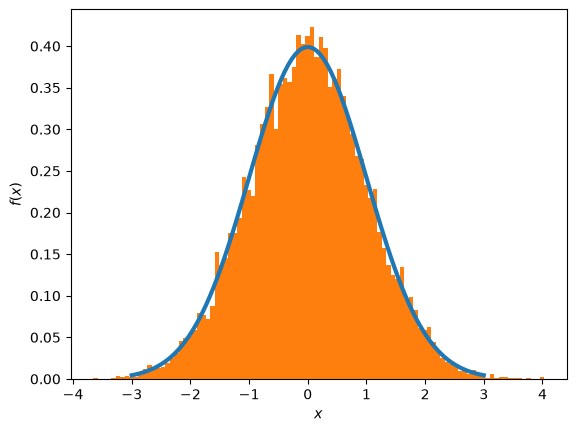

In [5]:
x = np.linspace(-3, 3, 100)
pdf = norm_rv.pdf(x)

# плотность 
plt.plot(x, pdf, lw=3)

# гистограмма, параметр density отнормировал её. 
plt.hist(sample, bins=100, density=True);

plt.ylabel('$f(x)$')
plt.xlabel('$x$');

Построим по выборке эмпирическую функцию распределения. 

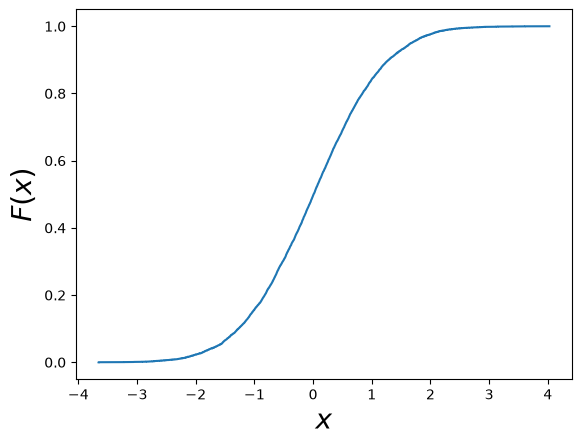

In [6]:
# для построения ECDF используем библиотеку statsmodels
from statsmodels.distributions.empirical_distribution import ECDF

ecdf = ECDF(sample)   # строим эмпирическую функцию по выборке

plt.step(ecdf.x, ecdf.y)
plt.ylabel('$F(x)$', fontsize=20)
plt.xlabel('$x$', fontsize=20);

Можно нарисовать её на одной картинке с теоретической:

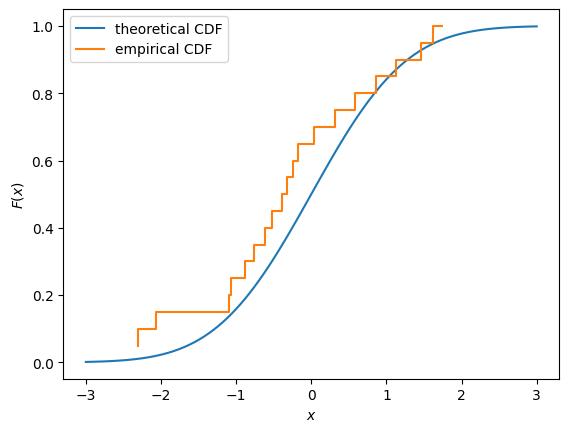

In [22]:
x = np.linspace(-3, 3, 100)

# теоретическа cdf 
cdf = norm_rv.cdf(x)
plt.plot(x, cdf, label='theoretical CDF')

# эмпирическая сdf
ecdf = ECDF(sample)
plt.step(ecdf.x, ecdf.y, label='empirical CDF')

plt.ylabel('$F(x)$')
plt.xlabel('$x$')
plt.legend(loc='upper left');